# Linear dependence of the K factors (K = 30, τ = 10, in-sample)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *
from src.config import CHARS_CLEAN_PARQUET, TARGET_COL, feature_cols
from src.models.spherical_kmeans import fit_monthly
from src.portfolio.optimiser import SpecBBacktester

K, TAU = 30, 10
df = pl.read_parquet(CHARS_CLEAN_PARQUET).filter(pl.col("DATE") <= IS_END_DATE)
features = feature_cols(df.columns)
groups = [g for _, g in df.group_by("DATE", maintain_order=True)]
months = [g.select(features).to_numpy() for g in groups]
dates = [g["DATE"][0] for g in groups]

W_all, c_all, F = [], [], []
for t, (model, _) in enumerate(fit_monthly(months, K)):
    Pi = model.transform(months[t], TAU)
    W_tilde = Pi - Pi.mean(axis=0)
    c = np.abs(W_tilde).sum(axis=0)
    W = W_tilde / c
    W_all.append(W); c_all.append(c); F.append(W.T @ groups[t][TARGET_COL].to_numpy())
F = np.array(F)
print(F.shape)

(191, 30)


## 1. The c-weighted sum of all factor portfolios is exactly zero every month

In [2]:
residual = [np.abs(W @ c).max() for W, c in zip(W_all, c_all)]
print(f"largest |Σ_k c_k w_k| over all stocks and months: {max(residual):.1e}")

largest |Σ_k c_k w_k| over all stocks and months: 1.4e-15


## 2. Eigenvalues of the factor return covariance: all K factors vs dropping one

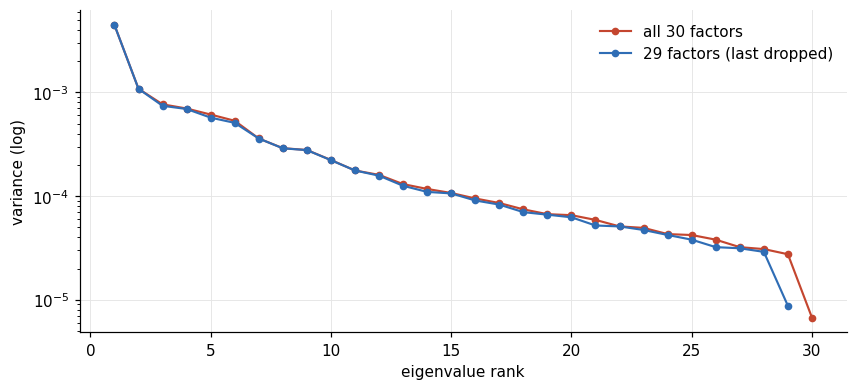

factors,largest_eigenvalue,smallest_eigenvalue,largest_over_smallest
i64,f64,f64,f64
30,0.0045,0.0000,663.8405
29,0.0045,0.0000,511.0340


In [3]:
ev_k = np.linalg.eigvalsh(np.cov(F.T))[::-1]
ev_k1 = np.linalg.eigvalsh(np.cov(F[:, :-1].T))[::-1]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, K + 1), ev_k, marker="o", ms=4, color="#c4462f", lw=1.4, label=f"all {K} factors")
ax.plot(range(1, K), ev_k1, marker="o", ms=4, color=BLUE, lw=1.4, label=f"{K - 1} factors (last dropped)")
ax.set_yscale("log"); ax.set_xlabel("eigenvalue rank"); ax.set_ylabel("variance (log)"); ax.legend(frameon=False); plt.show()
pl.DataFrame({"factors": [K, K - 1], "largest_eigenvalue": [ev_k[0], ev_k1[0]], "smallest_eigenvalue": [ev_k[-1], ev_k1[-1]],
              "largest_over_smallest": [ev_k[0] / ev_k[-1], ev_k1[0] / ev_k1[-1]]})

## 3. Gross exposure of the equal-weight mix of all K factors (old tuning score) vs one factor

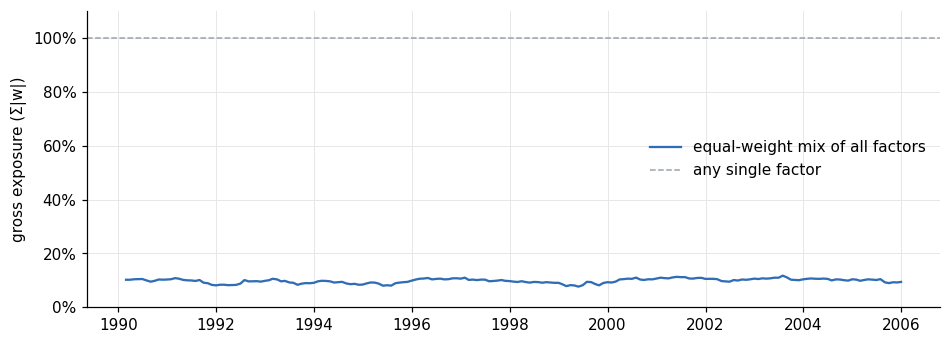

portfolio,median_gross,monthly_return_std
str,f64,f64
"""equal-weight mix""",0.0998,0.0010
"""average single factor""",1.0000,0.0180


In [4]:
eq_gross = np.array([np.abs(W.mean(axis=1)).sum() for W in W_all])
eq_ret = F.mean(axis=1)
fig, ax = plt.subplots(figsize=(10, 3.5))
d = pl.Series(dates).cast(pl.String).str.to_date("%Y%m%d")
ax.plot(d, eq_gross, color=BLUE, lw=1.5, label="equal-weight mix of all factors")
ax.axhline(1.0, color=GREY, lw=1, ls="--", label="any single factor")
ax.set_ylim(0, 1.1); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("gross exposure (Σ|w|)"); ax.legend(frameon=False); plt.show()
pl.DataFrame({"portfolio": ["equal-weight mix", "average single factor"],
              "median_gross": [np.median(eq_gross), 1.0],
              "monthly_return_std": [eq_ret.std(), F.std(axis=0).mean()]})

## 4. Same stock holdings from different factor weights: a vs a + λ·c

In [5]:
W, c = W_all[100], c_all[100]
a = np.zeros(K); a[:5] = 0.2
rows = []
for lam in [0.0, 0.002, 0.005, 0.01]:
    a2 = a + lam * c
    rows.append({"lambda": lam, "factor_gross_|a|": np.abs(a2).sum(), "max_|a_k|": np.abs(a2).max(),
                 "stock_gross_|Wa|": np.abs(W @ a2).sum(), "max_stock_diff_vs_lambda0": np.abs(W @ a2 - W @ a).max()})
pl.DataFrame(rows)

lambda,factor_gross_|a|,max_|a_k|,stock_gross_|Wa|,max_stock_diff_vs_lambda0
f64,f64,f64,f64,f64
0.0000,1.0000,0.2000,0.6742,0.0000
0.0020,8.3396,0.5529,0.6742,0.0000
0.0050,19.3490,1.0822,0.6742,0.0000
0.0100,37.6980,1.9643,0.6742,0.0000


## 5. Optimiser (default γ, κ) run in-sample with all K factors vs K−1

In [6]:
def run(n_factors):
    frame = pl.DataFrame(F[:, :n_factors], schema=[f"f{k}" for k in range(n_factors)]).with_columns(pl.Series("DATE", dates))
    res = SpecBBacktester().run_backtest(frame)
    A = res["weights_df"].drop("DATE").to_numpy()
    start = len(dates) - A.shape[0]
    stock_w = [W_all[start + i][:, :n_factors] @ A[i] for i in range(A.shape[0])]
    permnos = [groups[start + i]["permno"].to_numpy() for i in range(A.shape[0])]
    stock_turn = [np.nan]
    for i in range(1, len(stock_w)):
        prev = dict(zip(permnos[i - 1], stock_w[i - 1])); cur = dict(zip(permnos[i], stock_w[i]))
        stock_turn.append(sum(abs(cur.get(p, 0) - prev.get(p, 0)) for p in set(prev) | set(cur)))
    return {"a_gross": np.abs(A).sum(1), "stock_gross": np.array([np.abs(w).sum() for w in stock_w]),
            "factor_turnover": res["returns_df"]["turnover"].to_numpy(), "stock_turnover": np.array(stock_turn),
            "sharpe": res["metrics"]["Sharpe Ratio"], "dates": d[start:]}
runs = {f"all {K}": run(K), f"{K - 1} (one dropped)": run(K - 1)}

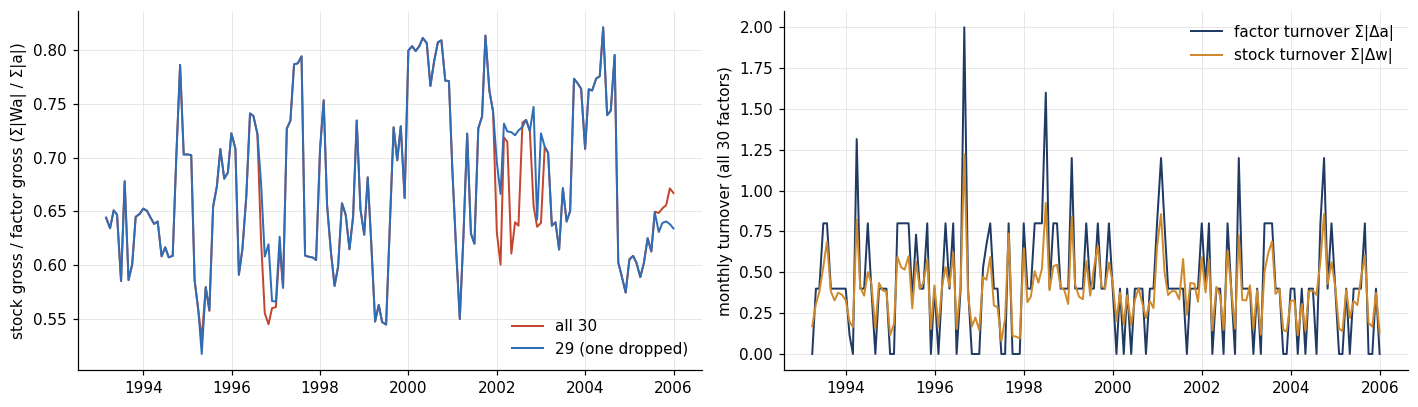

factors,median_factor_gross,median_stock_gross,median_factor_turnover,median_stock_turnover,sharpe_net_of_factor_costs
str,f64,f64,f64,f64,f64
"""all 30""",1.0000,0.6519,0.4000,0.3831,0.3694
"""29 (one dropped)""",1.0000,0.6557,0.4000,0.3845,0.3698


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for (name, r), color in zip(runs.items(), ["#c4462f", BLUE]):
    axes[0].plot(r["dates"], r["stock_gross"] / r["a_gross"], color=color, lw=1.3, label=name)
r = runs[f"all {K}"]
axes[1].plot(r["dates"][1:], r["factor_turnover"][1:], color="#1f3b63", lw=1.3, label="factor turnover Σ|Δa|")
axes[1].plot(r["dates"][1:], r["stock_turnover"][1:], color="#d08a2c", lw=1.3, label="stock turnover Σ|Δw|")
axes[0].set_ylabel("stock gross / factor gross (Σ|Wa| / Σ|a|)"); axes[0].legend(frameon=False)
axes[1].set_ylabel(f"monthly turnover (all {K} factors)"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
pl.DataFrame([{"factors": name, "median_factor_gross": np.median(r["a_gross"]), "median_stock_gross": np.median(r["stock_gross"]),
               "median_factor_turnover": np.nanmedian(r["factor_turnover"][1:]), "median_stock_turnover": np.nanmedian(r["stock_turnover"][1:]),
               "sharpe_net_of_factor_costs": r["sharpe"]} for name, r in runs.items()])